# Day 34 — Practice ANSWERS
### More Than One Column

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

| Part | What it asks you to do | How many |
|---|---|---|
| **A** | Work it out — pen and paper | 8 |
| **B** | Find the mistake in a short program | 4 |
| **C** | Write the code yourself | 5 |
| **D** | Challenge | 2 |

### How to work

**Part A needs no computer** for most questions. Work it out, then run the cell to check.

Three questions to keep asking:

- What else is in the model? A coefficient means nothing without that list.
- Are two of my columns saying **the same thing**?
- Did I measure the gain on rows the model **never saw**?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (8, 3.2)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("ready")

ready


---
# Part A — Work it out

A delivery company fits this model to predict how many **minutes** a delivery takes:

```
minutes  =  2.4 × distance_km  +  1.8 × items  −  3.1 × rider_experience_years
            +  6.5 × is_dinner  +  11.0
```

Four input columns, one intercept.

### A1 · Predict one delivery

An order goes **5 km**, has **4 items**, the rider has **2 years** of experience, and it is
**dinner time** (`is_dinner = 1`).

How many minutes? Show each multiplication.

In [2]:
def predict(distance_km, items, experience, is_dinner):
    return (2.4*distance_km + 1.8*items - 3.1*experience
            + 6.5*is_dinner + 11.0)

print(predict(5, 4, 2, 1))

30.5


| piece | arithmetic | value |
|---|---|---|
| distance | 2.4 × 5 | +12.0 |
| items | 1.8 × 4 | +7.2 |
| experience | −3.1 × 2 | −6.2 |
| dinner | 6.5 × 1 | +6.5 |
| intercept | | +11.0 |
| **total** | | **30.5 minutes** |

That is the entire prediction: **four multiplications and one addition.**

### A2 · Say each coefficient out loud

Write one sentence for each of the four coefficients. Each sentence must contain the
clause that makes it true.

| column | sentence |
|---|---|
| `distance_km` | "Each extra kilometre adds about **2.4 minutes**, for two deliveries identical in items, rider experience and time of day." |
| `items` | "Each extra item adds about **1.8 minutes**, everything else held the same." |
| `rider_experience_years` | "Each extra year of experience saves about **3.1 minutes**, holding distance, items and time of day constant." |
| `is_dinner` | "A dinner-time delivery takes about **6.5 minutes longer** than an identical one at any other hour." |

**The clause is not decoration.** "Each extra kilometre adds 2.4 minutes" on its own is a
different — and probably false — claim, because longer deliveries also tend to be bigger
ones.

Note `is_dinner` is a yes/no column, so its coefficient is not "per unit of dinner". It is
the gap between the two groups, with everything else matched.

### A3 · What does the intercept mean here?

What would 11.0 describe, and should you quote it?

**11.0 minutes** is what the model predicts for a delivery of **0 km, 0 items, by a rider
with 0 years of experience, not at dinner time.**

**Do not quote it.** A delivery of zero kilometres carrying zero items is not a delivery.
Nothing like that row exists in any dataset.

The intercept is doing a job — it holds the whole model at the right height — but it is
arithmetic, not a finding. Same rule as Day 33: check whether **zero is inside your data**
for every column at once. Here it is not.

### A4 · Two deliveries

Delivery P: 8 km, 3 items, rider with 1 year, not dinner.
Delivery Q: 8 km, 3 items, rider with 5 years, not dinner.

How much faster is Q, and why can you answer without computing either one?

In [3]:
print("P:", predict(8, 3, 1, 0))
print("Q:", predict(8, 3, 5, 0))
print("difference:", round(predict(8, 3, 5, 0) - predict(8, 3, 1, 0), 2))

P: 32.5
Q: 20.1
difference: -12.4


**Q is 12.4 minutes faster.**

And you did not need either prediction: the two deliveries differ in **exactly one
column**, by 4 years. So the difference is the coefficient times the gap:

```
−3.1 × 4  =  −12.4 minutes
```

**That is what "holding everything else constant" buys you.** When two rows match on every
other column, the coefficient does the whole job on its own.

### A5 · Which column matters most?

A colleague looks at the four coefficients — 2.4, 1.8, −3.1, 6.5 — and says
*"dinner time matters most, it has the biggest number."*

Is he right?

**No, and the reasoning is the mistake from the lecture.**

A coefficient is **per unit of its own column**, and the four columns have completely
different units and ranges:

| column | realistic range | biggest effect it can produce |
|---|---|---|
| `distance_km` | 1 to 15 km | 2.4 × 14 ≈ **34 minutes** |
| `items` | 1 to 12 | 1.8 × 11 ≈ **20 minutes** |
| `rider_experience_years` | 0 to 10 | 3.1 × 10 ≈ **31 minutes** |
| `is_dinner` | 0 or 1 | 6.5 × 1 = **6.5 minutes** |

`is_dinner` has the biggest coefficient and the **smallest** actual influence, because it
can only ever move by 1.

**The fix:** scale every column before comparing, so each coefficient means "per standard
deviation" and they are all in the same units. Or do the rough version above — coefficient
× the column's realistic spread.

### A6 · A sign that flips

A model of exam marks is fitted twice:

| model | coefficient on `hours_of_sleep` |
|---|---|
| sleep alone | **+2.1** marks per hour |
| sleep **and** `hours_of_study` | **−0.4** marks per hour |

A student says one of the two must be wrong. Is she right? Explain what is happening.

**She is not right. Both numbers can be correct**, and they almost certainly are.

They answer two different questions:

- **+2.1** answers: *"Do students who sleep more get better marks?"* Yes — and the likely
  reason is that organised students both sleep well **and** study a lot.
- **−0.4** answers: *"Among students who study the same number of hours, does sleeping
  more help?"* Apparently not, slightly the reverse — a day has only 24 hours, so at a
  fixed amount of study, extra sleep is coming out of something else.

The second model **holds study hours constant**, and that changes the question completely.

### What you would report

Not "sleep is bad for marks". That would be a serious misreading. You would say:

> Sleep and marks move together, but once study time is accounted for the association
> disappears. The apparent benefit of sleep in the simple model is mostly study time
> wearing a disguise.

**This is exactly the bedrooms example from the lecture.** A coefficient is a property of
the column *and* every other column in the model.

### A7 · One-hot and the missing category

A model of flat rent includes a `city_area` column with four values: **Andheri**, **Powai**,
**Thane**, **Bandra**. After `pd.get_dummies(..., drop_first=True)` the model reports:

```
city_area_Bandra   +9,400
city_area_Powai    +2,100
city_area_Thane    −3,800
```

a. Which area is missing, and why?
b. What does `+9,400` actually mean?
c. How much more is a Bandra flat than a Powai flat, all else equal?

**a. Andheri is missing** — `drop_first=True` dropped the first category alphabetically.
It has not been thrown away. It has become the **baseline**: a flat in Andheri has 0 in all
three columns, so its coefficients contribute nothing.

If all four columns were kept they would add to 1 for every row — the same information
twice, which is the `sqft`/`sqm` problem from the lecture.

**b. +9,400 means:** a Bandra flat rents for about ₹9,400 more than **an Andheri flat of
the same size, age and everything else in the model.** Not ₹9,400 more than average — more
than the dropped baseline.

**c. ₹9,400 − ₹2,100 = ₹7,300 more.**

Both are measured against Andheri, so the comparison between them is just the difference.
This also shows why the choice of baseline does not matter: it cancels.

**And note:** change `drop_first` to drop Bandra instead, and all three numbers change —
but every single prediction stays identical.

### A8 · Which model would you ship?

Three models of the same data, scored on rows they never saw:

| | columns | R² studied | R² hidden |
|---|---|---|---|
| **A** | 4 | 0.81 | 0.79 |
| **B** | 12 | 0.88 | 0.80 |
| **C** | 60 | 0.97 | 0.62 |

Which do you ship, and what is going on in each?

**Ship B — but only just, and it is worth arguing about.**

**Model C is the easy call: reject it.** 0.97 on the rows it studied and 0.62 on new ones.
With 60 columns it has enough freedom to bend around the training rows. It is memorising.

**A versus B is the real question.** B is better on hidden rows — 0.80 against 0.79 — so
on the evidence, B. But:

- **The gain is 0.01.** That is well inside the wobble you would get from a different
  split. Re-run with `random_state=1` and it could easily reverse.
- **B costs eight more columns**, which means eight more things to collect, clean, explain
  and keep working in production.
- **A's gap is 0.02; B's is 0.08.** B is already starting to lean on its training rows.

**What a professional would actually do:** stop guessing from one split. Cross-validate
both (Day 36), and if they are still within noise of each other, **ship A** — fewer
columns, easier to explain, less to break.

**The principle:** when two models score the same, the simpler one wins. "Within noise" is
not a tie you break with the bigger number.

---
# Part B — Find the mistake

Four short programs. Each runs cleanly and reports something misleading.

In [4]:
# ---------------------------------------------------------------
# 400 flats. B1 to B4 all use `flats`.
# ---------------------------------------------------------------
rng = np.random.default_rng(3415)
n = 400

sqft     = rng.normal(950, 250, n).clip(400, 2000).round(0)
bedrooms = np.clip(np.round(sqft/440 + rng.normal(0, 0.7, n)), 1, 5)
age      = rng.uniform(0, 28, n).round(0)
rent     = (9500 + 22*sqft - 2800*bedrooms - 240*age + rng.normal(0, 3000, n)).round(0)

flats = pd.DataFrame({"sqft": sqft, "bedrooms": bedrooms, "age_years": age, "rent": rent})
flats.head()

,sqft,bedrooms,age_years,rent
0,1039.0,2.0,2.0,25435.0
1,715.0,2.0,16.0,19399.0
2,878.0,2.0,26.0,14959.0
3,734.0,2.0,26.0,11877.0
4,854.0,3.0,11.0,18058.0


### B1 · "Age barely matters"

In [5]:
X = flats[["sqft", "bedrooms", "age_years"]]
y = flats["rent"]

model = LinearRegression().fit(X, y)

for name, value in zip(X.columns, model.coef_):
    print(f"{name:<12} {value:>+10.2f}")
print()
print("Conclusion: age_years has the smallest effect, so we can drop it.")   # <-- look here

sqft             +20.93
bedrooms       -2491.98
age_years       -234.54

Conclusion: age_years has the smallest effect, so we can drop it.


**The problem:** the conclusion compares **raw** coefficients across columns with
completely different units.

`age_years` runs from 0 to 28. `sqft` runs from 400 to 2000. A coefficient of −240 per
year and +22 per square foot are not comparable numbers — one year and one square foot are
nothing like the same amount of change.

**The fix:** scale the columns, or multiply each coefficient by its column's spread.

In [6]:
scaler = StandardScaler().fit(X)
scaled_model = LinearRegression().fit(scaler.transform(X), y)

out = pd.DataFrame({
    "column": X.columns,
    "raw": model.coef_.round(2),
    "column spread (sd)": X.std().values.round(1),
    "scaled": scaled_model.coef_.round(0),
})
print(out.to_string(index=False))

   column      raw  column spread (sd)  scaled
     sqft    20.93               249.3  5210.0
 bedrooms -2491.98                 0.8 -2109.0
age_years  -234.54                 7.8 -1838.0


```
     column      raw  column spread (sd)   scaled
       sqft    20.93               249.3   5210.0
   bedrooms -2491.98                 0.8  -2109.0
  age_years  -234.54                 7.8  -1838.0
```

**Age is not the least important column. It is a close second to bedrooms.**

Its coefficient looks tiny because **a year is a small unit**. But ages vary by 7.8 years
across the data, so the column moves the rent by about **₹1,838**. Bedrooms, despite a
coefficient more than ten times larger, vary by only 0.8 — so it moves the rent by
**₹2,109**, barely more.

Raw, bedrooms looked **10.6 times** more important than age. Scaled, it is **1.15 times**.

**Dropping `age_years` would have been close to dropping the second most useful column in
the model** — and the raw coefficients said to do exactly that.

### B2 · The helpful intern adds a column

In [7]:
work = flats.copy()
work["sqm"] = (work.sqft * 0.0929).round(2)      # the same area, in square metres

cols = ["sqft", "sqm", "bedrooms", "age_years"]

for seed in [0, 1, 2]:
    a, b, c, d = train_test_split(work[cols], work.rent, test_size=0.3, random_state=seed)
    m = LinearRegression().fit(a, c)
    print(f"split {seed}:  sqft {m.coef_[0]:>+11.2f}   sqm {m.coef_[1]:>+12.2f}"
          f"   hidden R² {m.score(b, d):.4f}")

split 0:  sqft     +706.49   sqm     -7373.36   hidden R² 0.7394
split 1:  sqft      -76.34   sqm     +1053.70   hidden R² 0.6970
split 2:  sqft   +10445.21   sqm   -112219.63   hidden R² 0.7452


**The problem:** `sqm` is `sqft` multiplied by a constant. It carries **no new
information whatsoever**.

The model has to decide how to split the credit between two identical columns, and since
any split gives the same predictions, it picks arbitrarily — differently on every split.

**The fix:** drop one of them. Keep whichever is easier to explain.

In [8]:
for seed in [0, 1, 2]:
    a, b, c, d = train_test_split(work[cols], work.rent, test_size=0.3, random_state=seed)
    m = LinearRegression().fit(a, c)
    combined = m.coef_[0] + m.coef_[1]*0.0929
    print(f"split {seed}: combined effect per sqft = {combined:>+8.2f}")

print()
clean = ["sqft", "bedrooms", "age_years"]
for seed in [0, 1, 2]:
    a, b, c, d = train_test_split(work[clean], work.rent, test_size=0.3, random_state=seed)
    m = LinearRegression().fit(a, c)
    print(f"split {seed}: sqft alone (no sqm) = {m.coef_[0]:>+8.2f}   hidden R² {m.score(b, d):.4f}")

split 0: combined effect per sqft =   +21.51
split 1: combined effect per sqft =   +21.55
split 2: combined effect per sqft =   +20.01

split 0: sqft alone (no sqm) =   +21.51   hidden R² 0.7389
split 1: sqft alone (no sqm) =   +21.55   hidden R² 0.6971
split 2: sqft alone (no sqm) =   +19.95   hidden R² 0.7533


```
split 0: combined effect per sqft =   +21.51
split 1: combined effect per sqft =   +21.55
split 2: combined effect per sqft =   +20.01

split 0: sqft alone (no sqm) =   +21.51   hidden R² 0.7389
split 1: sqft alone (no sqm) =   +21.55   hidden R² 0.6971
split 2: sqft alone (no sqm) =   +19.95   hidden R² 0.7533
```

**Two things are now clear.**

The **combined** effect was stable all along — about **+₹21 per square foot** — and it is
exactly what the clean model reports. The information was never lost; it was just split
arbitrarily between two columns, and the split changed every time.

Look at how wild the individual numbers were: split 1 put `sqft` at **−76** and `sqm` at
**+1,054**; split 2 put them at **+10,445** and **−112,220**. Any of those could have gone
into a report as "the value of a square foot".

And the **hidden R² barely moved**: 0.7394 / 0.6970 / 0.7452 with `sqm`, against 0.7389 /
0.6971 / 0.7533 without. *(The third split differs by 0.008 — that is numerical wobble
from solving a system with two identical columns, not a real loss.)*

**Predictions: fine. Explanation: ruined.** That is multicollinearity in one line.

### B3 · "Every column we add makes it better"

In [9]:
noise_rng = np.random.default_rng(5)
padded = flats.copy()
for j in range(25):
    padded[f"extra_{j}"] = noise_rng.normal(0, 1, n)     # pure random numbers

base_cols = ["sqft", "bedrooms", "age_years"]
all_cols = base_cols + [f"extra_{j}" for j in range(25)]

for cols_now in [base_cols, all_cols]:
    m = LinearRegression().fit(padded[cols_now], padded.rent)
    print(f"{len(cols_now):>2} columns  ->  R² {m.score(padded[cols_now], padded.rent):.4f}")
print()
print("Conclusion: more columns, better model.")    # <-- look here

 3 columns  ->  R² 0.7110
28 columns  ->  R² 0.7266

Conclusion: more columns, better model.


**The problem:** R² was measured on **the same rows the model learned from**, and twenty-five
of the columns are literally random numbers.

R² on training rows **can never go down** when you add a column — the model could always
set a useless coefficient to zero and match its old score. So it can only go up.

**The fix:** split, and score on the rows the model never saw.

In [10]:
for cols_now, label in [(base_cols, " 3 columns"), (all_cols, "28 columns")]:
    a, b, c, d = train_test_split(padded[cols_now], padded.rent, test_size=0.3, random_state=0)
    m = LinearRegression().fit(a, c)
    print(f"{label}:  studied {m.score(a, c):.4f}   hidden {m.score(b, d):.4f}"
          f"   miss ₹{mean_absolute_error(d, m.predict(b)):,.0f}")

 3 columns:  studied 0.6994   hidden 0.7389   miss ₹2,081
28 columns:  studied 0.7243   hidden 0.6941   miss ₹2,266


```
 3 columns:  studied 0.6994   hidden 0.7389   miss ₹2,081
28 columns:  studied 0.7243   hidden 0.6941   miss ₹2,266
```

On the studied rows the padded model looks **better** (0.724 vs 0.699). On rows it has
never seen it is **worse** (0.694 vs 0.739), and it misses by about **₹185 more per flat**.

Twenty-five columns of pure noise bought a fake improvement of **+0.025** and cost a real
one of **−0.045**.

**The habit:** never compare two models with different numbers of columns using R² on
training rows. The comparison is rigged in favour of the bigger model before you start.

### B4 · The report that goes to the landlord

In [11]:
m = LinearRegression().fit(flats[["sqft", "bedrooms", "age_years"]], flats.rent)
print(f"coefficient on bedrooms: {m.coef_[1]:+.2f}")
print()
print(f"REPORT: 'Bedrooms reduce rent by ₹{abs(m.coef_[1]):,.0f} each. We recommend")
print( "         converting all 3BHK units into 1BHK to raise income.'")

coefficient on bedrooms: -2491.98

REPORT: 'Bedrooms reduce rent by ₹2,492 each. We recommend
         converting all 3BHK units into 1BHK to raise income.'


**The problem is not the number — it is the sentence built on it, and the sentence has two
separate failures.**

**Failure 1 — the missing clause.** The coefficient is −₹1,511 *holding square footage
constant*. It does **not** say bedrooms reduce rent. It says that **at a fixed area**,
chopping the flat into more rooms makes them poky and worth less.

**Failure 2 — a coefficient is not an intervention.** Even read correctly, the model
describes how *existing* flats differ. It has nothing to say about what happens if you
*change* one. Converting a 3BHK to a 1BHK does not move that flat along a line the model
drew — it creates a kind of flat the model may never have seen.

**The fix:** report what was measured, not what you wish it implied.

In [12]:
# What the data actually says, with no model at all:
def by_bedrooms(df):
    g = df.groupby("bedrooms").agg(flats=("rent", "size"),
                                   avg_sqft=("sqft", "mean"),
                                   avg_rent=("rent", "mean")).round(0)
    return g[g.flats >= 5]          # ignore groups too small to mean anything

print("flats of similar size (850–1,150 sqft):")
print(by_bedrooms(flats[(flats.sqft >= 850) & (flats.sqft <= 1150)]).to_string())
print()
print("and across ALL flats, ignoring size:")
print(by_bedrooms(flats).to_string())

flats of similar size (850–1,150 sqft):
          flats  avg_sqft  avg_rent
bedrooms                           
1.0          31     949.0   24370.0
2.0          91     991.0   22467.0
3.0          53    1017.0   21392.0
4.0           7    1093.0   18945.0

and across ALL flats, ignoring size:
          flats  avg_sqft  avg_rent
bedrooms                           
1.0          87     752.0   19809.0
2.0         181     935.0   21093.0
3.0         107    1077.0   22062.0
4.0          24    1309.0   22557.0


```
flats of similar size (850–1,150 sqft):
          flats  avg_sqft  avg_rent
bedrooms
1.0          31     949.0   24370.0
2.0          91     991.0   22467.0
3.0          53    1017.0   21392.0
4.0           7    1093.0   18945.0

and across ALL flats, ignoring size:
          flats  avg_sqft  avg_rent
bedrooms
1.0          87     752.0   19809.0
2.0         181     935.0   21093.0
3.0         107    1077.0   22062.0
4.0          24    1309.0   22557.0
```

**Both tables are true, and they point in opposite directions.**

Across all flats, more bedrooms means more rent — because bigger flats have more bedrooms.
Among flats of a similar size, more bedrooms means slightly less.

### What the report should have said

> At a fixed floor area, flats divided into more bedrooms rent for about ₹2,500 less per
> extra bedroom — smaller rooms are worth less. This describes how existing flats differ;
> it is not evidence about what would happen if we renovated one. Before acting we would
> want to look at actual conversions.

### The rule

**A regression coefficient is a description, not a lever.** It tells you how rows that
already exist differ from each other. Turning it into "so we should change X" requires an
argument the model cannot supply — ideally an experiment.

---
# Part C — Write the code

Five tasks on one dataset.

In [13]:
# ---------------------------------------------------------------
# 600 used cars. C1 to C5 all use `cars`.
# ---------------------------------------------------------------
rng = np.random.default_rng(3410)
N = 600

age_years = rng.uniform(0, 14, N).round(1)
km_driven = (age_years*11000 + rng.normal(0, 18000, N)).clip(500, None).round(0)
engine_cc = rng.choice([800, 1000, 1200, 1500, 2000], N, p=[.15, .25, .3, .2, .1]).astype(float)
owners    = np.clip(np.round(1 + age_years/6 + rng.normal(0, 0.5, N)), 1, 4)
fuel      = rng.choice(["petrol", "diesel", "cng"], N, p=[.55, .35, .10])

bump = np.where(fuel == "diesel", 48000, np.where(fuel == "cng", -22000, 0))
price = (520000 - 31000*age_years - 0.42*km_driven + 150*engine_cc
         - 26000*owners + bump + rng.normal(0, 35000, N)).clip(40000, None).round(0)

cars = pd.DataFrame({"age_years": age_years, "km_driven": km_driven,
                     "engine_cc": engine_cc, "owners": owners,
                     "fuel": fuel, "price": price})
cars.head()

,age_years,km_driven,engine_cc,owners,fuel,price
0,8.8,92750.0,1200.0,1.0,petrol,354882.0
1,0.3,24702.0,800.0,1.0,diesel,548761.0
2,12.2,122193.0,1500.0,3.0,petrol,276918.0
3,13.9,134299.0,800.0,4.0,diesel,78115.0
4,13.4,159105.0,2000.0,3.0,petrol,215114.0


### C1 · Look first, including at the inputs

Do step 1 of the recipe properly:

- a scatter of each numeric column against `price`
- the correlation table **between the input columns**

Then write one sentence about what you see in the second one.

In [14]:
# your code here

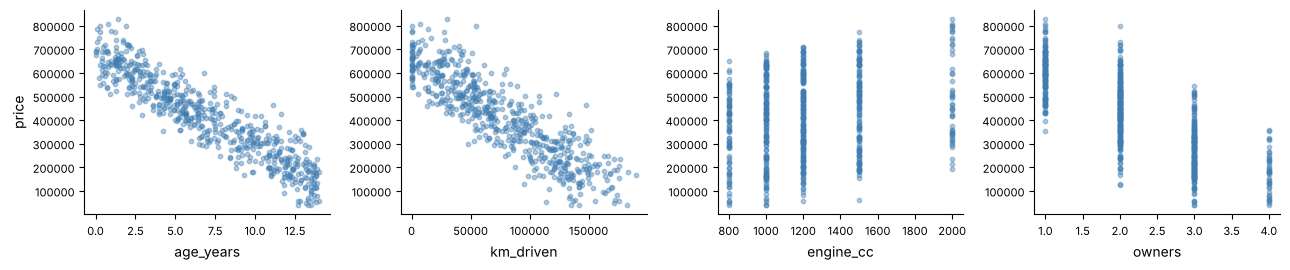

correlations between the INPUT columns:
           age_years  km_driven  engine_cc  owners
age_years       1.00       0.93       0.07    0.80
km_driven       0.93       1.00       0.05    0.73
engine_cc       0.07       0.05       1.00    0.06
owners          0.80       0.73       0.06    1.00


In [15]:
numeric = ["age_years", "km_driven", "engine_cc", "owners"]

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, name in zip(axes, numeric):
    ax.scatter(cars[name], cars.price, s=10, color="#3E7CB1", alpha=0.4)
    ax.set_xlabel(name, fontsize=10)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("price", fontsize=10)
plt.tight_layout(); plt.show()

print("correlations between the INPUT columns:")
print(cars[numeric].corr().round(2).to_string())

```
           age_years  km_driven  engine_cc  owners
age_years       1.00       0.93       0.07    0.80
km_driven       0.93       1.00       0.05    0.73
engine_cc       0.07       0.05       1.00    0.06
owners          0.80       0.73       0.06    1.00
```

**`age_years` and `km_driven` correlate at 0.93, and `age_years` and `owners` at 0.80.**

That makes sense — older cars have been driven further and passed through more hands. So
three of the four columns are partly telling the same story, and we should expect their
individual coefficients to be unstable and hard to separate.

**This is exactly what step 1 is for.** Ten seconds of looking has told us what to expect
before fitting anything.

### C2 · Encode the word column, then fit

One-hot `fuel`, split, fit, and print every coefficient with its name. Report R² on both
the studied and the hidden rows, plus the average miss in rupees.

In [16]:
# your code here

In [17]:
encoded = pd.get_dummies(cars[["age_years", "km_driven", "engine_cc", "owners", "fuel"]],
                         columns=["fuel"], drop_first=True).astype(float)
print("columns:", list(encoded.columns))
print()

a, b, c, d = train_test_split(encoded, cars.price, test_size=0.3, random_state=0)
m = LinearRegression().fit(a, c)

for name, value in zip(encoded.columns, m.coef_):
    print(f"   {name:<16} {value:>+13.2f}")
print(f"   {'intercept':<16} {m.intercept_:>+13.2f}")
print()
print(f"R² studied : {m.score(a, c):.4f}")
print(f"R² hidden  : {m.score(b, d):.4f}")
print(f"average miss: ₹{mean_absolute_error(d, m.predict(b)):,.0f}")

columns: ['age_years', 'km_driven', 'engine_cc', 'owners', 'fuel_diesel', 'fuel_petrol']

   age_years            -29907.84
   km_driven                -0.52
   engine_cc              +154.97
   owners               -24312.60
   fuel_diesel          +73015.70
   fuel_petrol          +27364.78
   intercept           +487697.29

R² studied : 0.9644
R² hidden  : 0.9626
average miss: ₹26,999


```
columns: ['age_years', 'km_driven', 'engine_cc', 'owners', 'fuel_diesel', 'fuel_petrol']

   age_years            -29907.84
   km_driven                -0.52
   engine_cc              +154.97
   owners               -24312.60
   fuel_diesel          +73015.70
   fuel_petrol          +27364.78
   intercept           +487697.29

R² studied : 0.9644
R² hidden  : 0.9626
average miss: ₹26,999
```

**`cng` is the dropped baseline**, so both fuel coefficients are measured against it: a
diesel car is worth about ₹73,000 more than a CNG car that is otherwise identical, and a
petrol car about ₹27,000 more.

Which means diesel is worth about **₹45,700 more than petrol** — the difference between
the two coefficients.

The gap between studied and hidden is **0.0018**. Six columns cannot memorise 420 rows.

### C3 · Which column matters most?

Rank the six columns by actual influence. Show both the raw and the scaled coefficients
side by side, and say which column the raw numbers would have misled you about.

In [18]:
# your code here

In [19]:
scaler = StandardScaler().fit(a)
scaled = LinearRegression().fit(scaler.transform(a), c)

table = pd.DataFrame({
    "column": encoded.columns,
    "raw": m.coef_.round(2),
    "scaled": scaled.coef_.round(0),
})
table["rank by raw"] = table.raw.abs().rank(ascending=False).astype(int)
table["rank by scaled"] = table.scaled.abs().rank(ascending=False).astype(int)
print(table.sort_values("rank by scaled").to_string(index=False))

     column       raw    scaled  rank by raw  rank by scaled
  age_years -29907.84 -124380.0            2               1
  engine_cc    154.97   50111.0            5               2
fuel_diesel  73015.70   34358.0            1               3
  km_driven     -0.52  -25317.0            6               4
     owners -24312.60  -21471.0            4               5
fuel_petrol  27364.78   13542.0            3               6


```
     column        raw    scaled  rank by raw  rank by scaled
  age_years  -29907.84 -124380.0            2               1
  engine_cc    +154.97  +50111.0            5               2
fuel_diesel  +73015.70  +34358.0            1               3
  km_driven      -0.52  -25317.0            6               4
     owners  -24312.60  -21471.0            4               5
fuel_petrol  +27364.78  +13542.0            3               6
```

**`km_driven` is the column the raw numbers would have ruined you on.** Its coefficient is
**−0.52** — dead last, and it looks like a rounding error next to +73,015 for diesel. But
kilometres vary by about 48,000 across the dataset, so the column actually moves the price
by around **₹25,000**, putting it fourth.

**`engine_cc` is the same story in reverse**: +155 looks trivial, but engine sizes span
1,200 cc, making it the second most influential column in the model.

And `fuel_diesel`, the biggest raw coefficient by far, drops to third once you account for
the fact that it can only ever be 0 or 1.

**Raw coefficients rank columns by their units. Scaled coefficients rank them by their
influence.** Only the second is what anybody meant to ask.

### C4 · Add the columns one at a time

Starting from `age_years` alone, add `km_driven`, then `engine_cc`, then `owners`, then
the fuel columns. Report the hidden R² and the average miss at each step.

Then answer: **did `km_driven` earn its place?**

In [20]:
# your code here

In [21]:
steps = [
    ["age_years"],
    ["age_years", "km_driven"],
    ["age_years", "km_driven", "engine_cc"],
    ["age_years", "km_driven", "engine_cc", "owners"],
    list(encoded.columns),
]

previous = None
for cols_now in steps:
    aa, bb, cc, dd = train_test_split(encoded[cols_now], cars.price,
                                      test_size=0.3, random_state=0)
    mm = LinearRegression().fit(aa, cc)
    score = mm.score(bb, dd)
    miss = mean_absolute_error(dd, mm.predict(bb))
    label = "+ fuel (one-hot)" if len(cols_now) == 6 else "+ " + cols_now[-1]
    if previous is None:
        label = "age_years only"
    change = "" if previous is None else f"  ({score - previous:+.4f})"
    print(f"{label:<22} hidden R² {score:.4f}{change}   miss ₹{miss:,.0f}")
    previous = score

age_years only         hidden R² 0.8452   miss ₹55,077
+ km_driven            hidden R² 0.8503  (+0.0050)   miss ₹54,250
+ engine_cc            hidden R² 0.9362  (+0.0860)   miss ₹36,525
+ owners               hidden R² 0.9421  (+0.0059)   miss ₹34,241
+ fuel (one-hot)       hidden R² 0.9626  (+0.0205)   miss ₹26,999


```
age_years only         hidden R² 0.8452   miss ₹55,077
+ km_driven            hidden R² 0.8503  (+0.0050)   miss ₹54,250
+ engine_cc            hidden R² 0.9362  (+0.0860)   miss ₹36,525
+ owners               hidden R² 0.9421  (+0.0059)   miss ₹34,241
+ fuel (one-hot)       hidden R² 0.9626  (+0.0205)   miss ₹26,999
```

### Did `km_driven` earn its place? Barely.

**+0.005**, and about **₹800** off the average miss. That is close to nothing — and C1 told
us why: `km_driven` correlates **0.93** with `age_years`, which was already in the model.
Almost everything it knows, age had already said.

Contrast `engine_cc`: **+0.086**, seventeen times bigger, and it correlates only 0.07 with
age. It is the one column carrying genuinely independent information.

### Would I drop `km_driven`?

**Probably not**, and this is a judgement call worth making out loud:

- it is free — already in the data, nothing extra to collect
- it does not hurt the hidden score
- a car with unusually high mileage *for its age* is exactly the case where it would
  matter, and those cars exist even if they are rare

**But I would never put it in a report as a finding.** "Each kilometre costs ₹0.52" is a
number the model cannot pin down separately from age, and I would say so.

### C5 · Price a specific car, and know when to refuse

Using your model from C2, price these three cars. For each one, decide whether you should
answer at all.

| | age | km | cc | owners | fuel |
|---|---|---|---|---|---|
| **A** | 6 years | 70,000 | 1,200 | 2 | petrol |
| **B** | 3 years | 160,000 | 1,500 | 1 | diesel |
| **C** | 25 years | 300,000 | 2,500 | 6 | petrol |

In [22]:
# your code here

In [23]:
for name in ["age_years", "km_driven", "engine_cc", "owners"]:
    print(f"   {name:<12} runs from {cars[name].min():>9,.0f} to {cars[name].max():>9,.0f}")
print()

candidates = pd.DataFrame([
    {"age_years": 6,  "km_driven": 70000,  "engine_cc": 1200, "owners": 2,
     "fuel_diesel": 0.0, "fuel_petrol": 1.0},
    {"age_years": 3,  "km_driven": 160000, "engine_cc": 1500, "owners": 1,
     "fuel_diesel": 1.0, "fuel_petrol": 0.0},
    {"age_years": 25, "km_driven": 300000, "engine_cc": 2500, "owners": 6,
     "fuel_diesel": 0.0, "fuel_petrol": 1.0},
])[encoded.columns]

for label, row in zip("ABC", candidates.itertuples(index=False)):
    print(f"car {label}: ₹{m.predict([list(row)])[0]:>12,.0f}")

   age_years    runs from         0 to        14
   km_driven    runs from       500 to   189,753
   engine_cc    runs from       800 to     2,000
   owners       runs from         1 to         4

car A: ₹     436,340
car B: ₹     595,448
car C: ₹    -147,990


In [24]:
# is each car's COMBINATION something we have seen?
print("cars in the data within 1 year of 3 years old AND over 140,000 km:")
near_B = cars[(cars.age_years.between(2, 4)) & (cars.km_driven > 140000)]
print("   ", len(near_B), "out of", len(cars))

cars in the data within 1 year of 3 years old AND over 140,000 km:
    0 out of 600


```
   age_years    runs from         0 to        14
   km_driven    runs from       500 to   189,753
   engine_cc    runs from       800 to     2,000
   owners       runs from         1 to         4

car A: ₹     436,340
car B: ₹     595,448
car C: ₹    -147,990
```

**Car A — answer it. ₹436,000.** Every value is comfortably inside its range, and a
6-year-old petrol hatchback with 70,000 km is an entirely ordinary combination.

**Car B — do not answer, even though every value is in range.** 3 years old is fine;
160,000 km is fine. But *together*? Checking the data: **0 cars out of 600** are 2–4 years
old with over 140,000 km. The combination has never been seen. This is the trap from the
lecture — a row can be inside every individual range and still be somewhere the model has
never been.

A car like that is real (an ex-taxi) and would be worth far less than ₹595,448. The model
has no way to know — and ₹595,448 is a *higher* price than it gave the perfectly ordinary
car A, which should be the thing that stops you.

**Car C — do not answer, and the model tells you so itself.** Every single value is outside
its range: 25 years (max 14), 300,000 km (max 190k), 2,500 cc (max 2,000), 6 owners (max
4). The prediction is **−₹147,990** — a negative price.

### The useful thing about car C

**A nonsense output is a gift.** It is the only one of the three failures you cannot
possibly miss. Car B is far more dangerous: it returns a confident, plausible, completely
unsupported number — and nobody would question it.

**So check the range for every column, and then ask separately whether the combination
ever occurred.**

---
# Part D — Challenge

Two tasks. Both are marked.

### D1 · Build multiple regression from scratch

Write **two** functions that fit a multi-column linear model, using no scikit-learn:

1. `fit_exact(X, y)` — the direct solution. Returns `(coefficients, intercept)`.
2. `fit_descent(X, y, rate, steps)` — gradient descent, generalised from Day 33.

Then prove both match `LinearRegression` on a dataset with **four** input columns.

**Marks are for:**
- both working for any number of columns, not just four
- `fit_descent` reporting its progress so a reader can see it converge
- handling the scale problem — `km_driven` is in the tens of thousands while `owners` is
  1 to 4, and plain gradient descent will struggle with that

*Hint for part 1: `np.linalg.lstsq` solves it, if you first add a column of ones to stand
in for the intercept.*

In [25]:
demo = encoded[["age_years", "km_driven", "engine_cc", "owners"]].values
demo_y = cars.price.values
print(demo.shape, demo_y.shape)

(600, 4) (600,)


In [26]:
# your two functions here

In [27]:
def fit_exact(X, y):
    """Direct least-squares solution. Works for any number of columns."""
    X = np.asarray(X, float)
    y = np.asarray(y, float)

    # a column of ones lets the intercept be solved for like any other coefficient
    ones = np.ones((len(X), 1))
    design = np.hstack([ones, X])

    solution, *_ = np.linalg.lstsq(design, y, rcond=None)
    return solution[1:], solution[0]        # coefficients, intercept

In [28]:
def fit_descent(X, y, rate=0.1, steps=4000, report=(1, 10, 100, 1000, 4000)):
    """Day 33's loop, with one coefficient per column.

    Gradient descent needs the columns on a similar scale (Day 32), so we scale
    inside the function and convert the answer back to the original units at the
    end. That way the caller never has to think about it.
    """
    X = np.asarray(X, float)
    y = np.asarray(y, float)
    n, k = X.shape

    centre, spread = X.mean(axis=0), X.std(axis=0)
    spread[spread == 0] = 1.0                 # a constant column would divide by zero
    Xs = (X - centre) / spread

    w = np.zeros(k)
    b = 0.0
    for step in range(1, steps + 1):
        error = (Xs @ w + b) - y
        w -= rate * (2/n) * (Xs.T @ error)
        b -= rate * (2/n) * error.sum()
        if step in report:
            sse = float(((Xs @ w + b - y) ** 2).sum())
            print(f"   step {step:>5}:  total squared error {sse:>18,.0f}")

    # undo the scaling, so the coefficients are in the caller's units
    coefficients = w / spread
    intercept = b - (w * centre / spread).sum()
    return coefficients, intercept

In [29]:
print("gradient descent, converging:")
d_coef, d_int = fit_descent(demo, demo_y)

e_coef, e_int = fit_exact(demo, demo_y)
sk = LinearRegression().fit(demo, demo_y)

names = ["age_years", "km_driven", "engine_cc", "owners"]
out = pd.DataFrame({
    "column":   names,
    "my exact": e_coef.round(4),
    "my descent": d_coef.round(4),
    "sklearn":  sk.coef_.round(4),
})
print()
print(out.to_string(index=False))
print()
print(f"intercepts:  exact {e_int:,.4f}   descent {d_int:,.4f}   sklearn {sk.intercept_:,.4f}")

gradient descent, converging:
   step     1:  total squared error 71,223,976,611,997
   step    10:  total squared error  2,443,459,001,621
   step   100:  total squared error  1,031,510,640,779
   step  1000:  total squared error  1,011,850,808,031
   step  4000:  total squared error  1,011,850,808,028

   column    my exact  my descent     sklearn
age_years -30887.2063 -30887.2063 -30887.2063
km_driven     -0.4481     -0.4481     -0.4481
engine_cc    160.4519    160.4519    160.4519
   owners -23642.1064 -23642.1064 -23642.1064

intercepts:  exact 518,047.3280   descent 518,047.3280   sklearn 518,047.3280


In [30]:
# prove the functions are general: a different dataset, SIX columns, random signs
gen = np.random.default_rng(2024)
Xg = gen.normal(0, 1, (300, 6)) * gen.uniform(1, 500, 6)      # wildly different scales
yg = Xg @ np.array([3.1, -0.4, 12.0, 0.0, -7.7, 2.2]) + 55 + gen.normal(0, 8, 300)

mine = fit_exact(Xg, yg)
theirs = LinearRegression().fit(Xg, yg)
print("six columns, scales from 1 to 500:")
print("   biggest coefficient difference:", f"{np.abs(mine[0] - theirs.coef_).max():.2e}")
print("   intercept difference          :", f"{abs(mine[1] - theirs.intercept_):.2e}")

six columns, scales from 1 to 500:
   biggest coefficient difference: 1.24e-14
   intercept difference          : 3.13e-13


### The result

```
gradient descent, converging:
   step     1:  total squared error 71,223,976,611,997
   step    10:  total squared error  2,443,459,001,621
   step   100:  total squared error  1,031,510,640,779
   step  1000:  total squared error  1,011,850,808,031
   step  4000:  total squared error  1,011,850,808,028

   column    my exact  my descent     sklearn
age_years -30887.2063 -30887.2063 -30887.2063
km_driven     -0.4481     -0.4481     -0.4481
engine_cc    160.4519    160.4519    160.4519
   owners -23642.1064 -23642.1064 -23642.1064

intercepts:  exact 518,047.3280   descent 518,047.3280   sklearn 518,047.3280

six columns, scales from 1 to 500:
   biggest coefficient difference: 1.24e-14
   intercept difference          : 3.13e-13
```

**All three agree to four decimal places**, and on the six-column test with scales spanning
1 to 500 the exact solver matches scikit-learn to about 1e-14 — floating-point noise, not
disagreement.

*(These coefficients differ slightly from C2's because this fit uses all 600 cars, while
C2 fitted on the 70% training split.)*

### The three things that earn the marks

**1. The column of ones.** `fit_exact` does not treat the intercept specially. Glue a
column of 1s onto X and the intercept becomes just another coefficient, because
`1 × intercept = intercept` for every row. One line, and the whole problem becomes a single
`lstsq` call.

**2. Scaling inside `fit_descent`.** This is the part most attempts get wrong. Try it
without scaling:

`km_driven` runs to 190,000 while `owners` runs to 4. The gradient for `km_driven` is tens
of thousands of times larger, so any learning rate small enough to keep it stable leaves
`owners` crawling — and any rate fast enough for `owners` makes `km_driven` explode to
`inf` within a few steps.

Scaling inside the function, then converting back at the end, means the **caller never has
to know**. That is the right place to put it.

The conversion back is worth reading carefully:

```python
coefficients = w / spread
intercept    = b - (w * centre / spread).sum()
```

The first line undoes the division. The second undoes the subtraction — every column that
was shifted by its mean has to give that shift back to the intercept.

**3. Generality.** Both functions take any `X` with any number of columns. The six-column
test with random signs and wild scales is what proves it, and a function that only works on
the dataset you wrote it for is not a function.

### The honest observation

`fit_exact` is instant and exact. `fit_descent` needs a few thousand steps, a learning
rate you had to choose, and a scaling trick to work at all.

**For linear regression, the exact solver wins outright** — which is why `sklearn` uses
one. Gradient descent is here because it is the method that still exists when the exact
solution does not: for logistic regression tomorrow, and for every neural network after
that.

### D2 · A model that blames the nurses

A hospital analytics team reports this to the board:

> *"We modelled patient deaths across 400 ward-shifts using beds, nurses on duty and
> equipment age. The model explains 60% of the variation on data it has never seen. The
> clearest finding is **nurses on duty**: each additional nurse on a shift is associated
> with **0.66 more deaths**. We recommend reviewing whether current staffing levels are
> excessive."*

The regression is correctly fitted. The split is correct. There is no bug in the code.

**Your tasks:**

1. Run it and confirm the numbers.
2. The dataset contains one column the team did **not** put in the model. Find it, and
   show what happens when you include it.
3. Prove *why* its absence produced that result — with evidence, not just assertion.
4. Write four or five sentences to send back to the board.

*Hints, in increasing order of giving it away: look at what columns exist · ask what
decides how many nurses a ward gets · compare wards that are similar in that respect.*

In [31]:
rng = np.random.default_rng(5440)
n = 400

patient_severity = rng.uniform(1, 10, n).round(1)      # 1 = minor, 10 = critical
beds             = rng.integers(14, 41, n).astype(float)
nurses_on_duty   = (beds*0.16 + patient_severity*1.05
                    + rng.normal(0, 0.9, n)).clip(2, None).round(0)
equipment_age    = rng.uniform(0, 15, n).round(1)

deaths = (1.5 + 1.42*patient_severity - 0.55*nurses_on_duty
          + 0.09*beds + 0.06*equipment_age
          + rng.normal(0, 1.1, n)).clip(0, None).round(0)

wards = pd.DataFrame({"beds": beds, "nurses_on_duty": nurses_on_duty,
                      "equipment_age": equipment_age,
                      "patient_severity": patient_severity, "deaths": deaths})
wards.head()

,beds,nurses_on_duty,equipment_age,patient_severity,deaths
0,37.0,8.0,1.0,2.3,3.0
1,38.0,13.0,1.4,6.5,7.0
2,28.0,16.0,3.7,9.2,6.0
3,15.0,13.0,8.5,9.7,11.0
4,33.0,15.0,1.4,9.9,12.0


In [32]:
their_cols = ["beds", "nurses_on_duty", "equipment_age"]

a, b, c, d = train_test_split(wards[their_cols], wards.deaths, test_size=0.3, random_state=0)
their_model = LinearRegression().fit(a, c)

for name, value in zip(their_cols, their_model.coef_):
    print(f"   {name:<18} {value:>+9.4f}")
print(f"   {'intercept':<18} {their_model.intercept_:>+9.4f}")
print()
print(f"R² on hidden rows : {their_model.score(b, d):.4f}")

   beds                 -0.1247
   nurses_on_duty       +0.6614
   equipment_age        +0.0746
   intercept            +2.8311

R² on hidden rows : 0.6032


In [33]:
# your investigation here

In [34]:
# Step 1 - what columns are actually available?
print("columns in the dataset :", list(wards.columns))
print("columns in their model :", their_cols)
print()
print("NOT USED: patient_severity  <- how sick this ward's patients are")

columns in the dataset : ['beds', 'nurses_on_duty', 'equipment_age', 'patient_severity', 'deaths']
columns in their model : ['beds', 'nurses_on_duty', 'equipment_age']

NOT USED: patient_severity  <- how sick this ward's patients are


In [35]:
# Step 2 - put it in and refit.
all_cols = ["beds", "nurses_on_duty", "equipment_age", "patient_severity"]

a2, b2, c2, d2 = train_test_split(wards[all_cols], wards.deaths, test_size=0.3, random_state=0)
full_model = LinearRegression().fit(a2, c2)

print(f"{'column':<20}{'their model':>14}{'with severity':>16}")
print("-" * 50)
for i, name in enumerate(all_cols):
    theirs = their_model.coef_[i] if i < 3 else float("nan")
    theirs_str = f"{theirs:>+14.4f}" if i < 3 else f"{'not used':>14}"
    print(f"{name:<20}{theirs_str}{full_model.coef_[i]:>+16.4f}")
print()
print(f"{'R² on hidden rows':<20}{their_model.score(b, d):>14.4f}{full_model.score(b2, d2):>16.4f}")
print(f"{'average miss':<20}{mean_absolute_error(d, their_model.predict(b)):>14.3f}"
      f"{mean_absolute_error(d2, full_model.predict(b2)):>16.3f}")

column                 their model   with severity
--------------------------------------------------
beds                       -0.1247         +0.0776
nurses_on_duty             +0.6614         -0.5133
equipment_age              +0.0746         +0.0608
patient_severity          not used         +1.3505

R² on hidden rows           0.6032          0.8248
average miss                 1.332           0.911


In [36]:
# Step 3a - WHY? Because nurses are ASSIGNED according to severity.
staffing = LinearRegression().fit(wards[["patient_severity", "beds"]], wards.nurses_on_duty)
print("can we predict the nurse count from severity and ward size?")
print(f"   nurses = {staffing.coef_[0]:.3f} × severity + {staffing.coef_[1]:.3f} × beds "
      f"+ {staffing.intercept_:.3f}")
print(f"   R² = {staffing.score(wards[['patient_severity','beds']], wards.nurses_on_duty):.4f}"
      "   <- that is a staffing POLICY, visible in the data")
print()
print(f"correlation between nurses_on_duty and patient_severity: "
      f"{wards.nurses_on_duty.corr(wards.patient_severity):.4f}")

can we predict the nurse count from severity and ward size?
   nurses = 1.038 × severity + 0.164 × beds + -0.090
   R² = 0.9137   <- that is a staffing POLICY, visible in the data

correlation between nurses_on_duty and patient_severity: 0.8679


In [37]:
# Step 3b - and the evidence with no regression at all:
#           inside a narrow severity band, more nurses means FEWER deaths.
print("within wards of similar patient severity:")
for lo, hi in [(2, 4), (4, 6), (6, 8), (8, 10)]:
    band = wards[(wards.patient_severity >= lo) & (wards.patient_severity < hi)]
    mb = LinearRegression().fit(band[["nurses_on_duty"]], band.deaths)
    print(f"   severity {lo}–{hi} ({len(band):>3} wards): "
          f"nurses coefficient {mb.coef_[0]:>+7.3f}")

within wards of similar patient severity:
   severity 2–4 (106 wards): nurses coefficient  -0.164
   severity 4–6 ( 80 wards): nurses coefficient  -0.198
   severity 6–8 ( 76 wards): nurses coefficient  -0.169
   severity 8–10 ( 87 wards): nurses coefficient  -0.042


In [38]:
# Step 4 - what the recommendation would have cost.
print("if a ward adds 4 nurses, the change in deaths the model predicts:")
print(f"   their model (no severity) : {4*their_model.coef_[1]:+.2f}  -> 'cut staffing'")
print(f"   with severity included    : {4*full_model.coef_[1]:+.2f}  -> 'add staffing'")

if a ward adds 4 nurses, the change in deaths the model predicts:
   their model (no severity) : +2.65  -> 'cut staffing'
   with severity included    : -2.05  -> 'add staffing'


### What the numbers show

```
column                 their model   with severity
--------------------------------------------------
beds                       -0.1247         +0.0776
nurses_on_duty             +0.6614         -0.5133
equipment_age              +0.0746         +0.0608
patient_severity          not used         +1.3505

R² on hidden rows           0.6032          0.8248
average miss                 1.332           0.911
```

**The nurse coefficient goes from +0.66 to −0.51.** Not smaller — the opposite sign.

And the model with severity is also simply **better**: R² 0.825 against 0.603, and it
misses by 0.91 deaths instead of 1.33.

### Why the missing column did that

The answer is in how nurses are allocated:

```
nurses = 1.038 × severity + 0.164 × beds − 0.090      R² = 0.9137
correlation between nurses_on_duty and patient_severity: 0.8679
```

**The hospital assigns more nurses to sicker wards.** That is not a quirk of the data — it
is a sensible staffing policy, and it is legible in the numbers with R² of 0.91.

So `nurses_on_duty` was acting as a **stand-in for severity**. The model had no column for
"how sick are these patients", and the nurse count was the best available proxy. It dutifully
reported that wards with more nurses have more deaths — which is true, and which means
nothing at all about what nurses do.

### The proof that needs no model

Compare wards that are **already similar in severity**:

```
within wards of similar patient severity:
   severity 2–4 (106 wards): nurses coefficient  -0.164
   severity 4–6 ( 80 wards): nurses coefficient  -0.198
   severity 6–8 ( 76 wards): nurses coefficient  -0.169
   severity 8–10 ( 87 wards): nurses coefficient  -0.042
```

**Every band is negative** — and in the full dataset the coefficient was **+0.66**. Simply
comparing like with like is enough to reverse the sign, with no regression involved.

Two honest caveats:

- **The within-band numbers are much smaller than −0.51.** Severity still varies inside
  each band, so each comparison is only partly holding it still. The full model, which
  holds it exactly constant, is the sharper estimate.
- **The 8–10 band is only −0.042**, close to zero. The most critical wards are also where
  severity varies most steeply within the band, so that comparison is the muddiest of the
  four. It is weak evidence on its own; it is the pattern across all four that matters.

### What the recommendation would have cost

```
if a ward adds 4 nurses, the change in deaths the model predicts:
   their model (no severity) : +2.65  -> 'cut staffing'
   with severity included    : -2.05  -> 'add staffing'
```

The board was about to be advised to **reduce** staffing on the strength of a model whose
sign was backwards.

### The reply to the board

> The +0.66 is real but it is not about nurses. Our own staffing policy assigns more nurses
> to sicker wards — severity and ward size predict the nurse count with an R² of 0.91 — so
> in a model with no severity column, `nurses_on_duty` is standing in for how ill the
> patients are. Adding `patient_severity`, which is already in the dataset, flips the nurse
> coefficient to **−0.51** and lifts the model's accuracy on unseen shifts from 0.60 to
> **0.82**. Looking only at wards with comparable severity, the association is negative in
> every band we checked. The evidence points the other way: on this data, four extra nurses
> are associated with about **two fewer deaths**, not two more.

### The idea to take away

**An omitted column does not leave a hole. It leaves its job to whichever column it
correlates with.**

That is the day's lesson with the stakes turned up. The sign flip in the lecture cost
nothing — a bedroom coefficient. Here, reading the same flip wrongly would have meant
advising a hospital to cut nursing staff.

**So before you report any coefficient, ask: what decides this column's value? If the
answer is "something else that also affects the outcome", that something else belongs in
the model.**

---
## Before you hand it in

- For every coefficient you quote: did you say **what else is in the model**?
- Did you **scale** before comparing coefficient sizes?
- Did you check the correlations **between the inputs**, not just with the answer?
- Did you measure every gain on rows the model **never saw**?
- For every prediction: is each value in range, **and did that combination ever occur**?
- Did you say "associated with" rather than "causes"?

Four numbers worth carrying away:

- Nurses: **+0.66** without severity, **−0.51** with it. The same column, the opposite
  advice, and one of them would have cut hospital staffing.
- Twenty-five junk columns raised training R² from **0.699 to 0.724** and lowered the
  honest score from **0.739 to 0.694**.
- `km_driven` has the smallest raw coefficient in the car model (**−0.52**) and the fourth
  largest influence. `fuel_diesel` has the largest raw coefficient and the third.
- `sqft` and `sqm` left the hidden R² **completely unchanged** and made the coefficients
  meaningless.

Answers will be shared after class.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*